# OpenVINO IR YOLO + ResNet Inference Demo

This notebook runs YOLO and the 3D ResNet regressor from OpenVINO IR files, displays YOLO detections, and prints a compact preview of ResNet outputs for easy device-to-device comparison.

## 1. Configure the experiment

Set the model paths, target devices, image selection, and post-processing thresholds here. Keeping these values together makes it easy to repeat the same inference on CPU, GPU, or NPU and compare the resulting detections and timings.

In [1]:
from pathlib import Path
import importlib
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import openvino as ov
import torch

def find_repository_root(start_path):
    for candidate in (start_path, *start_path.parents):
        if (candidate / 'utils').is_dir() and (candidate / 'library').is_dir():
            return candidate
    raise RuntimeError('Could not find the repository root from the notebook working directory.')

ROOT = find_repository_root(Path.cwd().resolve())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils.augmentations import letterbox
from utils.general import non_max_suppression, scale_coords
from library.Calib import get_P
from library.Math import calc_location
import library.Plotting as plotting
plot_3d_box = importlib.reload(plotting).plot_3d_box
from script.ClassAverages import ClassAverages
from script.Dataset import generate_bins

YOLO_MODEL = ROOT / 'weights/openvino/yolov5s_int8.xml'
RESNET_MODEL = ROOT / 'weights/openvino/resnet18_int8.xml'
CALIB_FILE = ROOT / 'eval/camera_cal/calib_cam_to_cam.txt'
YOLO_DEVICE = 'CPU'
RESNET_DEVICE = 'CPU'
IMAGE_PATH = None  # Set to a specific image path, or leave None to use the first image in eval/image_2.
MAX_DETECTIONS = 16  # Maximum number of YOLO crops sent to the batched ResNet request.
IMG_SIZE = 640
CONF_THRES = 0.25
IOU_THRES = 0.45
CLASSES = [0, 2, 3, 5]  # person, car, motorcycle, bus
COCO_NAMES = {0: 'person', 2: 'car', 3: 'motorcycle', 5: 'bus'}

print(f'YOLO model:      {YOLO_MODEL}')
print(f'ResNet model:    {RESNET_MODEL}')
print(f'Calibration file: {CALIB_FILE}')
print(f'YOLO device:     {YOLO_DEVICE}')
print(f'ResNet device:   {RESNET_DEVICE}')
print(f'Max detections:  {MAX_DETECTIONS}')

C:\Users\helena\repos\YOLO3D\utils\general.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg


YOLO model:      C:\Users\helena\repos\YOLO3D\weights\openvino\yolov5s_int8.xml
ResNet model:    C:\Users\helena\repos\YOLO3D\weights\openvino\resnet18_int8.xml
Calibration file: C:\Users\helena\repos\YOLO3D\eval\camera_cal\calib_cam_to_cam.txt
YOLO device:     CPU
ResNet device:   CPU
Max detections:  16


## 2. Prepare inputs and post-process YOLO output

These helpers locate a test image, apply the repository's YOLO letterbox and normalization steps, compile the IR, run inference, and decode detections with the existing YOLOv5 non-maximum suppression utilities. The measured YOLO time covers the OpenVINO call, while decoding and drawing are handled separately.

## 3. Reconstruct 3D geometry

The YOLO boxes are only the 2D measurements. Camera calibration supplies the projection matrix and each box's viewing ray; ResNet supplies orientation and dimensions. The repository's `calc_location` and `plot_3d_box` helpers then estimate the object location and draw the cuboid on the original image.

In [2]:
def calc_theta_ray(image_bgr, box_2d, proj_matrix):
    width = image_bgr.shape[1]
    fovx = 2 * np.arctan(width / (2 * proj_matrix[0][0]))
    center = (box_2d[1][0] + box_2d[0][0]) / 2
    dx = center - (width / 2)
    angle = np.arctan((2 * abs(dx) * np.tan(fovx / 2)) / width)
    return angle * (-1 if dx < 0 else 1)

def draw_3d_prediction(image_bgr, det, orient_output, conf_output, dim_output, proj_matrix, averages, angle_bins):
    box_2d = [(det['box'][0], det['box'][1]), (det['box'][2], det['box'][3])]
    bin_index = int(np.argmax(conf_output))
    orientation = orient_output[bin_index]
    alpha = np.arctan2(orientation[1], orientation[0]) + angle_bins[bin_index] - np.pi
    dimensions = dim_output + averages.get_item(det['label'])
    theta_ray = calc_theta_ray(image_bgr, box_2d, proj_matrix)
    location, _ = calc_location(dimensions, proj_matrix, box_2d, alpha, theta_ray)
    plot_3d_box(image_bgr, proj_matrix, alpha + theta_ray, dimensions, location, fill_front=False)
    return alpha, theta_ray, location, dimensions

In [3]:
def find_image(image_path=None):
    if image_path is not None:
        path = Path(image_path)
        if not path.exists():
            raise FileNotFoundError(path)
        return path

    candidates = []
    for pattern in ('eval/image_2/*.png', 'eval/image_2/*.jpg', 'eval/image_2/*.jpeg', 'dataset/KITTI/testing/image_2/*.png'):
        candidates.extend(sorted(ROOT.glob(pattern)))
    if not candidates:
        raise FileNotFoundError('No image found. Set IMAGE_PATH in the first code cell.')
    return candidates[0]

def preprocess_yolo_bgr(image_bgr, img_size=640):
    resized = letterbox(image_bgr, new_shape=img_size, stride=32, auto=False)[0]
    rgb = resized[:, :, ::-1].transpose(2, 0, 1)
    tensor = np.ascontiguousarray(rgb, dtype=np.float32) / 255.0
    return tensor[None]

def compile_yolo(model_path, device):
    core = ov.Core()
    model = core.read_model(model_path)
    if device.upper() == 'NPU' and model.input(0).partial_shape.is_dynamic:
        # The NPU Python path requires bounded shapes. YOLO runs one image here,
        # so specialize its dynamic batch to the concrete batch-1 input.
        model.reshape({model.input(0).any_name: ov.PartialShape([1, 3, IMG_SIZE, IMG_SIZE])})
    return core.compile_model(model, device)

def run_yolo(compiled_model, image_bgr):
    input_data = preprocess_yolo_bgr(image_bgr, IMG_SIZE)
    start = time.perf_counter()
    results = compiled_model(input_data)
    wall_ms = (time.perf_counter() - start) * 1000
    pred = torch.from_numpy(results[compiled_model.output(0)])
    pred = non_max_suppression(pred, conf_thres=CONF_THRES, iou_thres=IOU_THRES, classes=CLASSES)[0]
    if pred is None or len(pred) == 0:
        return [], wall_ms
    pred[:, :4] = scale_coords(input_data.shape[2:], pred[:, :4], image_bgr.shape).round()
    detections = []
    for *xyxy, conf, cls in pred.tolist():
        x1, y1, x2, y2 = [int(v) for v in xyxy]
        cls_id = int(cls)
        detections.append({'box': [x1, y1, x2, y2], 'score': float(conf), 'class_id': cls_id, 'label': COCO_NAMES.get(cls_id, str(cls_id))})
    return detections, wall_ms

def draw_detections(image_bgr, detections):
    drawn = image_bgr.copy()
    for det in detections:
        x1, y1, x2, y2 = det['box']
        label = f"{det['label']} {det['score']:.2f}"
        cv2.rectangle(drawn, (x1, y1), (x2, y2), (0, 220, 80), 2)
        cv2.putText(drawn, label, (x1, max(y1 - 6, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 220, 80), 2)
    return drawn

## 3. Run YOLO and display detections

This cell selects the image, compiles the YOLO IR for the configured device, runs one inference, and draws the filtered detections. The displayed boxes are the final 2D inputs used to create crops for the 3D regressor.

Image: C:\Users\helena\repos\YOLO3D\eval\image_2\000010.png
YOLO detections: 13
YOLO wall latency: 59.09 ms


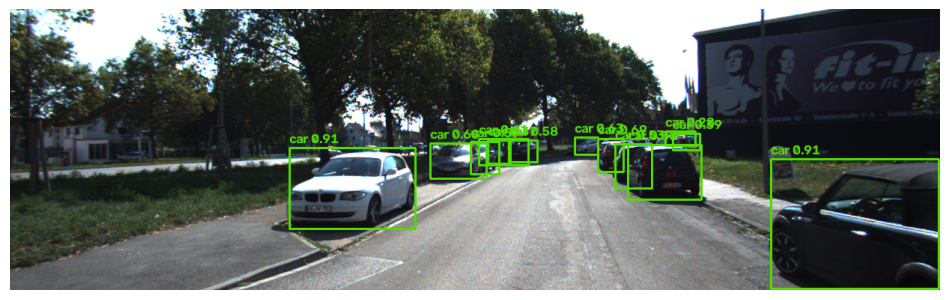

In [4]:
image_path = find_image(IMAGE_PATH)
image_bgr = cv2.imread(str(image_path))
if image_bgr is None:
    raise RuntimeError(f'Could not read image: {image_path}')

compiled_yolo = compile_yolo(YOLO_MODEL, YOLO_DEVICE)
detections, yolo_wall_ms = run_yolo(compiled_yolo, image_bgr)

print(f'Image: {image_path}')
print(f'YOLO detections: {len(detections)}')
print(f'YOLO wall latency: {yolo_wall_ms:.2f} ms')

display_bgr = draw_detections(image_bgr, detections)
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(display_bgr, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 4. Configure the bounded-dynamic ResNet IR request

The bounded model supports batch sizes from 1 through 16. For NPU, the notebook binds a concrete `ov.Tensor` for the crop batch; this is important because changing the shape of the request-owned tensor alone can leave NPU outputs at batch size 1. CPU and GPU use the request-owned tensor path.

In [5]:
class DynamicResNetIR:
    def __init__(self, model_path, device='NPU', input_size=224):
        self.input_size = input_size
        self.device = device.upper()
        core = ov.Core()
        model = core.read_model(model_path)
        model_shape = model.input(0).partial_shape

        if not model_shape.is_dynamic:
            raise ValueError(f'ResNet model must have a dynamic input shape, got {model_shape}')

        self.compiled_model = core.compile_model(model, self.device, {'PERFORMANCE_HINT': 'LATENCY'})
        self.request = self.compiled_model.create_infer_request()
        self.input_tensor = self.request.get_input_tensor()
        self.input_shape = (1, 3, input_size, input_size)
        self.input_tensor.shape = self.input_shape
        print(f'ResNet input shape: {model_shape} -> initial runtime {self.input_shape}')

    def crop_to_input(self, image_bgr, box):
        x1, y1, x2, y2 = box
        crop = image_bgr[y1:y2 + 1, x1:x2 + 1]
        crop = cv2.resize(crop, (self.input_size, self.input_size), interpolation=cv2.INTER_CUBIC)
        chw = crop.transpose(2, 0, 1)
        return np.ascontiguousarray(chw[None], dtype=np.uint8), crop

    def infer_batch(self, input_data):
        if self.device == 'NPU':
            # Explicit binding preserves the batch dimension for the bounded NPU model.
            self.request.set_input_tensor(ov.Tensor(input_data))
        else:
            if tuple(self.input_tensor.shape) != tuple(input_data.shape):
                self.input_tensor.shape = input_data.shape
            self.input_tensor.data[:] = input_data
        self.request.infer()
        outputs = [self.request.get_output_tensor(i).data.copy() for i in range(len(self.compiled_model.outputs))]
        input_batch = input_data.shape[0]
        output_batches = {output.shape[0] for output in outputs}
        if output_batches != {input_batch}:
            raise RuntimeError(
                f'{self.device} returned output batch sizes {sorted(output_batches)} '
                f'for input batch {input_batch}. The device/runtime did not preserve '
                'the dynamic batch; use a static model or run crops individually.'
            )
        return outputs

## 5. Run the regressor on a configurable crop batch

`MAX_DETECTIONS` controls how many YOLO detections are sent to ResNet, defaulting to 16. The selected crops are stacked into one tensor and inferred together using the model's bounded dynamic batch dimension. The output preview and reconstructed 3D geometry are shown per detection.

ResNet input shape: [?,3,224,224] -> initial runtime (1, 3, 224, 224)
ResNet batch shape: (13, 3, 224, 224)
#0 car score=0.915 alpha=-1.895
  location: [      6.839       1.165       9.945] dimensions: [      1.482       1.615       3.652]
  logits preview: [    0.94939,    -0.31942,     0.99259,     0.11959,       1.773,     -3.2367,   -0.044591,   -0.012235,   -0.028912]
#1 car score=0.907 alpha=2.144
  location: [     -2.798       0.891      13.918] dimensions: [      1.523       1.645       3.707]
  logits preview: [    0.95892,     0.35488,     0.95892,     0.61915,     -11.844,      10.729,  -0.0032681,     0.01824,    0.025872]
#2 car score=0.802 alpha=-1.618
  location: [      5.006       0.699      13.978] dimensions: [       1.49       1.612        3.31]
  logits preview: [    0.99806,   -0.047152,      0.9665,     0.25114,       11.05,     -11.255,   -0.035984,   -0.015002,    -0.37043]
#3 car score=0.688 alpha=-1.508
  location: [      8.168       0.388       30.24] dimensi

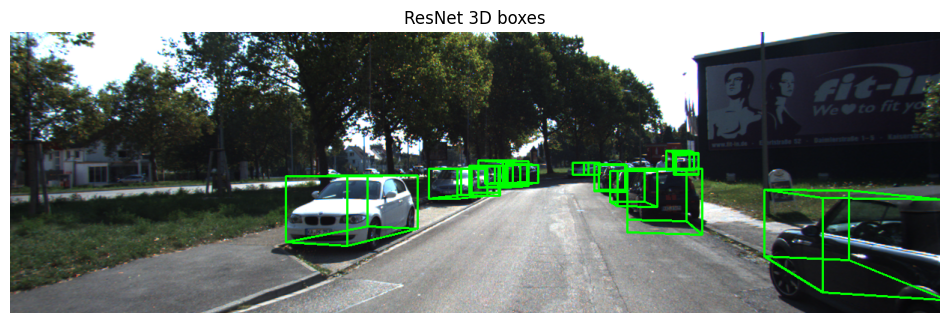

In [6]:
resnet = DynamicResNetIR(RESNET_MODEL, RESNET_DEVICE)
proj_matrix = get_P(CALIB_FILE)
averages = ClassAverages()
angle_bins = generate_bins(2)

# Set True to display the individual image crops sent to ResNet.
SHOW_CROPS = False

display_3d_bgr = image_bgr.copy()
selected_detections = [det for det in detections if averages.recognized_class(det['label'])][:MAX_DETECTIONS]
rows = []
crops_rgb = []

if selected_detections:
    crop_inputs = []
    for det in selected_detections:
        input_data, crop_bgr = resnet.crop_to_input(image_bgr, det['box'])
        crop_inputs.append(input_data)
        crops_rgb.append(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))

    # A dynamic-batch model can accept all selected crops in one request.
    batch_input = np.concatenate(crop_inputs, axis=0)
    outputs = resnet.infer_batch(batch_input)

    for idx, det in enumerate(selected_detections):
        orient_output = outputs[0][idx]
        conf_output = outputs[1][idx]
        dim_output = outputs[2][idx]
        preview = np.concatenate([output[idx].reshape(-1) for output in outputs])[:10]
        alpha, theta_ray, location, dimensions = draw_3d_prediction(
            display_3d_bgr,
            det,
            orient_output,
            conf_output,
            dim_output,
            proj_matrix,
            averages,
            angle_bins,
        )
        rows.append({
            'idx': idx,
            'label': det['label'],
            'score': det['score'],
            'alpha': alpha,
            'location': location,
            'dimensions': dimensions,
            'preview': np.array2string(preview, precision=5, separator=', '),
        })

if not rows:
    print('No recognized detections available for 3D ResNet inference.')
else:
    print(f'ResNet batch shape: {batch_input.shape}')
    for row in rows:
        print(f"#{row['idx']} {row['label']} score={row['score']:.3f} alpha={row['alpha']:.3f}")
        print(f"  location: {np.round(row['location'], 3)} dimensions: {np.round(row['dimensions'], 3)}")
        print(f"  logits preview: {row['preview']}")

    plt.figure(figsize=(12, 7))
    plt.imshow(cv2.cvtColor(display_3d_bgr, cv2.COLOR_BGR2RGB))
    plt.title('ResNet 3D boxes')
    plt.axis('off')
    plt.show()

    if SHOW_CROPS:
        cols = min(4, len(crops_rgb))
        rows_count = int(np.ceil(len(crops_rgb) / cols))
        plt.figure(figsize=(3 * cols, 3 * rows_count))
        for i, crop in enumerate(crops_rgb):
            plt.subplot(rows_count, cols, i + 1)
            plt.imshow(crop)
            plt.title(f"Crop #{i}: {rows[i]['label']}")
            plt.axis('off')
        plt.suptitle('ResNet input crops')
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

## 6. Benchmark repeated ResNet inference

This optional benchmark reuses the prepared crop batch. It performs configurable warm-up runs first, then records wall-clock latency and OpenVINO request latency over repeated inferences. The visualization above remains focused on detections and 3D geometry.

In [7]:
BENCHMARK_WARMUP_RUNS = 10
BENCHMARK_RUNS = 20

if not rows:
    print('No ResNet batch available for benchmarking.')
else:
    for _ in range(BENCHMARK_WARMUP_RUNS):
        if resnet.device == 'NPU':
            resnet.request.set_input_tensor(ov.Tensor(batch_input))
        else:
            if tuple(resnet.input_tensor.shape) != tuple(batch_input.shape):
                resnet.input_tensor.shape = batch_input.shape
            resnet.input_tensor.data[:] = batch_input
        resnet.request.infer()

    wall_timings = []
    device_timings = []
    for _ in range(BENCHMARK_RUNS):
        start = time.perf_counter()
        if resnet.device == 'NPU':
            resnet.request.set_input_tensor(ov.Tensor(batch_input))
        else:
            if tuple(resnet.input_tensor.shape) != tuple(batch_input.shape):
                resnet.input_tensor.shape = batch_input.shape
            resnet.input_tensor.data[:] = batch_input
        resnet.request.infer()
        wall_timings.append((time.perf_counter() - start) * 1000)
        device_timings.append(resnet.request.latency)

    print(f'Benchmark batch shape: {batch_input.shape}')
    print(f'Warm-up runs: {BENCHMARK_WARMUP_RUNS}')
    print(f'Benchmark runs: {BENCHMARK_RUNS}')
    print(f'Average wall latency:   {np.mean(wall_timings):.3f} ms')
    print(f'Median wall latency:    {np.median(wall_timings):.3f} ms')
    print(f'Average device latency: {np.mean(device_timings):.3f} ms')
    print(f'Median device latency:  {np.median(device_timings):.3f} ms')

Benchmark batch shape: (13, 3, 224, 224)
Warm-up runs: 10
Benchmark runs: 20
Average wall latency:   32.947 ms
Median wall latency:    29.700 ms
Average device latency: 32.722 ms
Median device latency:  29.479 ms


## 7. Compare PyTorch and OpenVINO 3D predictions

This comparison runs both the source PyTorch models and the OpenVINO models selected in the first cell on the same image. Each pipeline uses its own YOLO boxes, then ResNet estimates orientation and dimensions for those boxes. The side-by-side view helps reveal differences; one image is a visual check, not an accuracy measurement.

Fusing layers... 
Model Summary: 213 layers, 7225885 parameters, 0 gradients


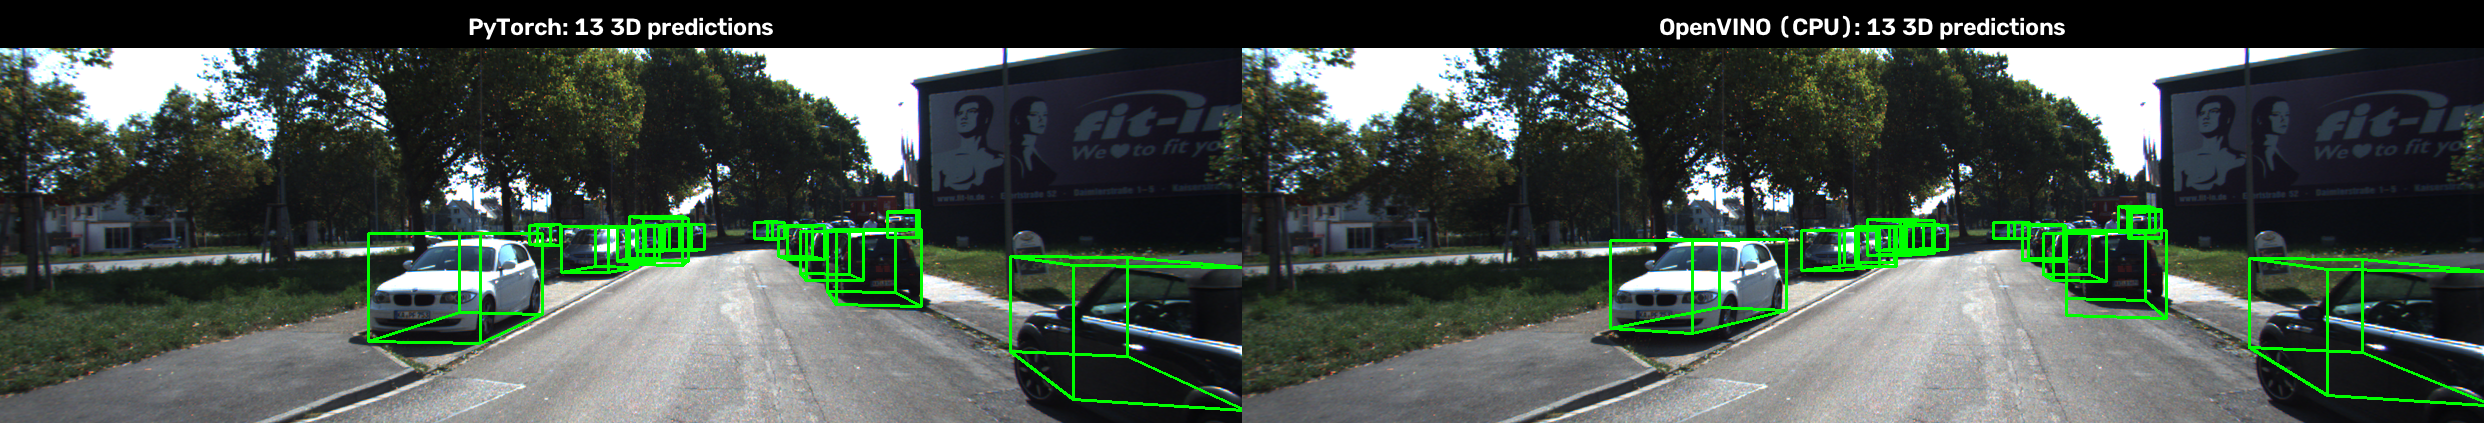

OpenVINO models: yolov5s_int8.xml, resnet18_int8.xml


In [8]:
import accuracy as accuracy_eval
from IPython.display import display
from PIL import Image

SOURCE_YOLO_MODEL = ROOT / 'weights/yolov5s.pt'
SOURCE_RESNET_MODEL = ROOT / 'weights/resnet18.pkl'

comparison_averages = ClassAverages()
comparison_angle_bins = generate_bins(2)


def run_comparison_pipeline(yolo_path, resnet_path, backend):
    yolo = accuracy_eval.YoloPredictor(yolo_path, backend, YOLO_DEVICE)
    resnet = accuracy_eval.ResNetPredictor(resnet_path, backend, RESNET_DEVICE)
    detections = yolo.predict(image_bgr, IMG_SIZE, CONF_THRES, IOU_THRES)
    rendered = image_bgr.copy()
    rows = []

    for x1, y1, x2, y2, score, class_id in detections.tolist():
        label = accuracy_eval.COCO_NAMES[int(class_id)]
        if not comparison_averages.recognized_class(label):
            continue
        det = {
            'box': [int(x1), int(y1), int(x2), int(y2)],
            'score': float(score),
            'class_id': int(class_id),
            'label': label,
        }
        rows.append(det)

    for det in rows:
        crop_input = resnet.preprocess(image_bgr, np.asarray(det['box']))
        outputs = resnet.predict(crop_input)
        orientation = next(output for output in outputs if output.ndim == 3)[0]
        confidence = next(output for output in outputs if output.ndim == 2 and output.shape[1] == 2)[0]
        dimensions = next(output for output in outputs if output.ndim == 2 and output.shape[1] == 3)[0]
        draw_3d_prediction(
            rendered,
            det,
            orientation,
            confidence,
            dimensions,
            proj_matrix,
            comparison_averages,
            comparison_angle_bins,
        )
    return rendered, rows


def add_panel_title(image, title):
    title_height = 48
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.8
    thickness = 2
    (text_width, text_height), _ = cv2.getTextSize(title, font, font_scale, thickness)
    titled_image = cv2.copyMakeBorder(
        image, title_height, 0, 0, 0, cv2.BORDER_CONSTANT, value=(0, 0, 0)
    )
    text_x = max((image.shape[1] - text_width) // 2, 8)
    text_y = (title_height + text_height) // 2
    cv2.putText(titled_image, title, (text_x, text_y), font, font_scale, (255, 255, 255), thickness)
    return titled_image


pytorch_3d_view, pytorch_3d_detections = run_comparison_pipeline(
    SOURCE_YOLO_MODEL, SOURCE_RESNET_MODEL, 'source'
)
openvino_3d_view, openvino_3d_detections = run_comparison_pipeline(
    YOLO_MODEL, RESNET_MODEL, 'openvino'
)

pytorch_panel = add_panel_title(
    pytorch_3d_view, f'PyTorch: {len(pytorch_3d_detections)} 3D predictions'
)
openvino_panel = add_panel_title(
    openvino_3d_view, f'OpenVINO ({YOLO_DEVICE}): {len(openvino_3d_detections)} 3D predictions'
)
comparison_panel = np.concatenate([pytorch_panel, openvino_panel], axis=1)
display(Image.fromarray(cv2.cvtColor(comparison_panel, cv2.COLOR_BGR2RGB)))

print(f"OpenVINO models: {Path(YOLO_MODEL).name}, {Path(RESNET_MODEL).name}")


## 8. Compare model accuracy on labeled KITTI images

This cell imports the evaluator already present in the repository root. YOLO is scored on labeled 2D boxes; ResNet is scored on ground-truth object crops, so its metrics isolate regression quality from detection quality. The Hugging Face KITTI train split is used because official KITTI test labels are unavailable. Increase the sample size for a more stable comparison.

In [ ]:
from types import SimpleNamespace
from IPython.display import display, Markdown
import pandas as pd

ACCURACY_LIMIT = 100
accuracy_args = SimpleNamespace(
    hf_dataset='nateraw/kitti',
    hf_split='train',
    hf_image_column='image',
    hf_label_column='label',
    shuffle_seed=None,
    shuffle_buffer_size=10000,
    limit=ACCURACY_LIMIT,
    batch_size=1,
    image_size=IMG_SIZE,
    conf_threshold=0.001,
    iou_threshold=0.6,
)

source_yolo_metrics = accuracy_eval.evaluate_yolo(
    accuracy_eval.YoloPredictor(SOURCE_YOLO_MODEL, 'source', YOLO_DEVICE), accuracy_args
)
openvino_yolo_metrics = accuracy_eval.evaluate_yolo(
    accuracy_eval.YoloPredictor(YOLO_MODEL, 'openvino', YOLO_DEVICE), accuracy_args
)
source_resnet_metrics = accuracy_eval.evaluate_resnet(
    accuracy_eval.ResNetPredictor(SOURCE_RESNET_MODEL, 'source', RESNET_DEVICE), accuracy_args
)
openvino_resnet_metrics = accuracy_eval.evaluate_resnet(
    accuracy_eval.ResNetPredictor(RESNET_MODEL, 'openvino', RESNET_DEVICE), accuracy_args
)

def make_comparison_table(metric_rows):
    return pd.DataFrame(metric_rows, columns=['Metric', 'PyTorch', 'OpenVINO', 'Difference']).set_index('Metric')


def format_comparison(source_value, openvino_value, precision=4, unit=''):
    format_string = f'{{:.{precision}f}}'
    return (
        format_string.format(source_value) + unit,
        format_string.format(openvino_value) + unit,
        format_string.format(openvino_value - source_value) + unit,
    )


yolo_rows = []
for metric_name, display_name in (
    ('precision', 'Precision'),
    ('recall', 'Recall'),
    ('map50', 'mAP@0.5'),
    ('map5095', 'mAP@0.5:0.95'),
):
    pytorch_value, openvino_value, difference = format_comparison(
        source_yolo_metrics[metric_name], openvino_yolo_metrics[metric_name]
    )
    yolo_rows.append((display_name, pytorch_value, openvino_value, difference))
yolo_rows.insert(0, ('Images evaluated', source_yolo_metrics['images'], openvino_yolo_metrics['images'], ''))

resnet_rows = [
    ('Images evaluated', source_resnet_metrics['images'], openvino_resnet_metrics['images'], ''),
    ('Objects evaluated', source_resnet_metrics['objects'], openvino_resnet_metrics['objects'], ''),
    ('Objects skipped', source_resnet_metrics['skipped_objects'], openvino_resnet_metrics['skipped_objects'], ''),
]
for metric_name, display_name, unit, precision in (
    ('orientation_mae_degrees', 'Orientation MAE', ' deg', 3),
    ('mean_dimension_mae', 'Mean dimension MAE', ' m', 4),
):
    pytorch_value, openvino_value, difference = format_comparison(
        source_resnet_metrics[metric_name], openvino_resnet_metrics[metric_name], precision, unit
    )
    resnet_rows.append((display_name, pytorch_value, openvino_value, difference))

for index, dimension_name in enumerate(('Height MAE', 'Width MAE', 'Length MAE')):
    pytorch_value, openvino_value, difference = format_comparison(
        source_resnet_metrics['dimensions_mae'][index],
        openvino_resnet_metrics['dimensions_mae'][index],
        precision=4,
        unit=' m',
    )
    resnet_rows.append((dimension_name, pytorch_value, openvino_value, difference))

In [12]:
display(Markdown('### YOLO detection'))
display(make_comparison_table(yolo_rows))
display(Markdown('### ResNet regression'))
display(make_comparison_table(resnet_rows))
display(Markdown(f"OpenVINO models: `{Path(YOLO_MODEL).name}`, `{Path(RESNET_MODEL).name}`"))

### YOLO detection

,PyTorch,OpenVINO,Difference
Metric,,,
Images evaluated,100,100,
Precision,0.7170,0.6904,-0.0266
Recall,0.5874,0.6060,0.0186
mAP@0.5,0.6368,0.6204,-0.0164
mAP@0.5:0.95,0.3477,0.3471,-0.0007


### ResNet regression

,PyTorch,OpenVINO,Difference
Metric,,,
Images evaluated,100,100,
Objects evaluated,469,469,
Objects skipped,31,31,
Orientation MAE,12.588 deg,13.941 deg,1.353 deg
Mean dimension MAE,0.1999 m,0.2045 m,0.0046 m
Height MAE,0.1116 m,0.1136 m,0.0019 m
Width MAE,0.0948 m,0.0949 m,0.0001 m
Length MAE,0.3934 m,0.4051 m,0.0117 m


OpenVINO models: `yolov5s_int8.xml`, `resnet18_int8.xml`